# 03.6 · The confusion matrix: accuracy, precision, recall, F1

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/06-confusion-matrix-metrics/lesson.ipynb)

Read the [README](README.md) and fill in the 20-row table by hand first. This notebook checks your counts, then does the same with scikit-learn, then on the real customer table.

## 1. The 20 customers and the rule

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
X20 = cust20[["visits_last_month", "days_since_last"]]
y20 = cust20["churned"]
cust20

,customer_id,visits_last_month,items_last_month,days_since_last,country,spend_next_month,churned
0,C001,2,2,55,UK,27.61,1
1,C002,11,8,44,FR,220.42,0
2,C003,10,6,22,DE,176.21,0
3,C004,7,6,58,UK,127.58,1
4,C005,7,5,25,FR,150.95,1
5,C006,13,7,20,FR,250.03,0
6,C007,2,2,54,UK,47.33,1
7,C008,10,5,22,UK,196.92,0
8,C009,3,3,5,DE,94.82,1
9,C010,2,1,28,UK,45.05,1


In [2]:
cust20["predicted"] = (cust20["days_since_last"] > 30).astype(int)

def box(row):
    return {(1, 1): "TP", (0, 1): "FP", (1, 0): "FN", (0, 0): "TN"}[(row["churned"], row["predicted"])]

cust20["box"] = cust20.apply(box, axis=1)
cust20[["customer_id", "days_since_last", "predicted", "churned", "box"]]

,customer_id,days_since_last,predicted,churned,box
0,C001,55,1,1,TP
1,C002,44,1,0,FP
2,C003,22,0,0,TN
3,C004,58,1,1,TP
4,C005,25,0,1,FN
5,C006,20,0,0,TN
6,C007,54,1,1,TP
7,C008,22,0,0,TN
8,C009,5,0,1,FN
9,C010,28,0,1,FN


## 2. Count the boxes and compute the four metrics by hand

In [3]:
def boxes(y_true, y_pred):
    """Count the four cells of the confusion matrix by hand."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    TP = int(((y_true == 1) & (y_pred == 1)).sum())
    FP = int(((y_true == 0) & (y_pred == 1)).sum())
    FN = int(((y_true == 1) & (y_pred == 0)).sum())
    TN = int(((y_true == 0) & (y_pred == 0)).sum())
    return TP, FP, FN, TN

def metrics_by_hand(TP, FP, FN, TN):
    acc = (TP + TN) / (TP + TN + FP + FN)
    prec = TP / (TP + FP) if TP + FP else float("nan")
    rec = TP / (TP + FN) if TP + FN else float("nan")
    f1 = 2 * TP / (2 * TP + FP + FN) if TP else 0.0
    return dict(accuracy=acc, precision=prec, recall=rec, f1=f1)

TP, FP, FN, TN = boxes(cust20["churned"], cust20["predicted"])
print(f"TP={TP}  FP={FP}  FN={FN}  TN={TN}   (sum {TP+FP+FN+TN})")
print()
print("                 predicted churn   predicted stay")
print(f"actually churned      {TP:>3}              {FN:>3}")
print(f"actually stayed       {FP:>3}              {TN:>3}")

TP=5  FP=3  FN=4  TN=8   (sum 20)

                 predicted churn   predicted stay
actually churned        5                4
actually stayed         3                8


In [4]:
for name, value in metrics_by_hand(TP, FP, FN, TN).items():
    print(f"{name:<10} {value:.3f}")

accuracy   0.650
precision  0.625
recall     0.556
f1         0.588


Compare with the README: accuracy 0.65, precision 0.625, recall 0.556, F1 0.588.

## 3. The lazy baseline: "nobody churns"

In [5]:
nobody = np.zeros(len(cust20), dtype=int)
TP0, FP0, FN0, TN0 = boxes(cust20["churned"], nobody)
print(f"TP={TP0}  FP={FP0}  FN={FN0}  TN={TN0}")
for name, value in metrics_by_hand(TP0, FP0, FN0, TN0).items():
    print(f"{name:<10} {value:.3f}")

TP=0  FP=0  FN=9  TN=11
accuracy   0.550
precision  nan
recall     0.000
f1         0.000


Accuracy 0.55 versus our rule's 0.65: only ten points apart. Recall 0 versus 0.556: the baseline never finds a single churner. (Precision is `nan` because it never flags anyone: 0 / 0.)

## 4. scikit-learn must agree

`confusion_matrix` lays the table out with **actual** classes as rows and **predicted** as columns, class 0 first: `[[TN, FP], [FN, TP]]`.

In [6]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

y_true, y_pred = cust20["churned"], cust20["predicted"]
print(confusion_matrix(y_true, y_pred))
print(f"accuracy  {accuracy_score(y_true, y_pred):.3f}")
print(f"precision {precision_score(y_true, y_pred):.3f}")
print(f"recall    {recall_score(y_true, y_pred):.3f}")
print(f"f1        {f1_score(y_true, y_pred):.3f}")

[[8 3]
 [4 5]]
accuracy  0.650
precision 0.625
recall    0.556
f1        0.588


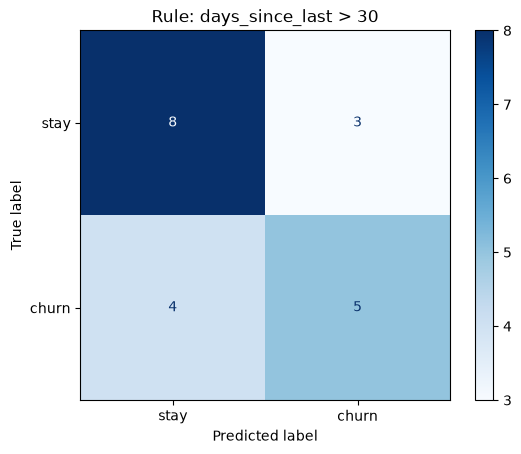

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=["stay", "churn"], cmap="Blues")
plt.title("Rule: days_since_last > 30"); plt.show()

## 5. `classification_report`: both classes at once

Precision and recall depend on which class you call positive. The report prints them for *each* class, plus `support` (how many true rows of that class) and two averages that 03.8 explains.

In [8]:
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred, target_names=["stay (0)", "churn (1)"]))

              precision    recall  f1-score   support

    stay (0)       0.67      0.73      0.70        11
   churn (1)       0.62      0.56      0.59         9

    accuracy                           0.65        20
   macro avg       0.65      0.64      0.64        20
weighted avg       0.65      0.65      0.65        20



Read the `churn (1)` row: 0.62 / 0.56 / 0.59 are your three numbers. The `stay (0)` row answers the opposite questions: of the customers we *cleared*, 67% really stayed; of the real stayers, 73% were cleared.

## 6. The 95% trap, in numbers

In [9]:
n, churners = 1000, 50
TP, FP, FN, TN = 0, 0, churners, n - churners          # "nobody churns"
m = metrics_by_hand(TP, FP, FN, TN)
print(f"accuracy {m['accuracy']:.1%}   recall {m['recall']:.0%}")

accuracy 95.0%   recall 0%


A model marketing would applaud, and that catches no one.

## 7. On the real ShopWave customers

Rebuild the customer table from 01.9 (features before 1 September 2011; `churned` = no purchase in the next three months), train the logistic regression from 03.4, and evaluate it on customers the model never saw.

> **About `train_test_split`.** We hold back 25% of customers and score the model only on those, because scoring a model on the rows it learned from is like marking your own homework. Module 04 explains this properly; for now, just know that `X_test` / `y_test` are "exam" customers the model never saw.

In [10]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd, numpy as np
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

xlsx = ensure_online_retail()
csv = xlsx.with_name("online_retail_2010_2011.csv")          # fast cache written by lesson 01.3
raw = pd.read_csv(csv, parse_dates=["InvoiceDate"]) if csv.exists() else pd.read_excel(xlsx, sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [11]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)
proba_test = logreg.predict_proba(X_test)[:, 1]          # P(churn) for each test customer
pred_test = logreg.predict(X_test)                        # same as (proba_test >= 0.5)

print(confusion_matrix(y_test, pred_test))
print(classification_report(y_test, pred_test, target_names=["stay", "churn"]))

[[323 145]
 [125 237]]
              precision    recall  f1-score   support

        stay       0.72      0.69      0.71       468
       churn       0.62      0.65      0.64       362

    accuracy                           0.67       830
   macro avg       0.67      0.67      0.67       830
weighted avg       0.68      0.67      0.68       830



Now put three candidates side by side: the lazy baseline, the recency rule from the by-hand section, and the model.

In [12]:
candidates = {
    "nobody churns":            np.zeros(len(y_test), dtype=int),
    "rule: days_since_last>90": (X_test["days_since_last"] > 90).astype(int).values,
    "logistic regression":      pred_test,
}
rows = []
for name, p in candidates.items():
    TP, FP, FN, TN = boxes(y_test, p)
    rows.append(dict(model=name, TP=TP, FP=FP, FN=FN, TN=TN, **metrics_by_hand(TP, FP, FN, TN)))
pd.DataFrame(rows).set_index("model").round(3)

,TP,FP,FN,TN,accuracy,precision,recall,f1
model,,,,,,,,
nobody churns,0,0,362,468,0.564,NaN,0.000,0.000
rule: days_since_last>90,194,150,168,318,0.617,0.564,0.536,0.550
logistic regression,237,145,125,323,0.675,0.620,0.655,0.637


Three different "best" models depending on which column you read. Accuracy favours whichever side has more customers; recall rewards flagging generously; precision rewards flagging carefully. None of them knows that a missed churner costs £60 and a wasted voucher £5. The next lesson fixes that.

## Quiz answers

1. It almost never flags anyone, but when it does it is nearly always right: a very cautious model that misses 90% of the positives.
2. **TP.** Precision = TP / (TP + FP); recall = TP / (TP + FN).
3. Accuracy 98% (every non-spam email is "correctly" passed); recall 0% (no spam caught).
4. The harmonic mean is dragged down by the smaller of the two. With precision 1.0 and recall 0.1 the ordinary average is 0.55, which hides the failure; the harmonic mean gives 0.18.
5. **Recall** for the churn class (accepting more false alarms), with the cost trade-off made explicit in 03.7.

**Next:** [03.7 ROC curves, AUC and choosing a threshold](../07-roc-auc-threshold/)